In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# --- Step 1: Load all datasets ---
reddit_train = pd.read_csv("/content/reddit_bert_train.csv")
reddit_val   = pd.read_csv("/content/reddit_bert_val.csv")
reddit_test  = pd.read_csv("/content/reddit_bert_test.csv")
twitter_all  = pd.read_csv("/content/twitter_bert.csv")

print("Reddit train:", reddit_train.shape)
print("Reddit val  :", reddit_val.shape)
print("Twitter all :", twitter_all.shape)


Reddit train: (87106, 3)
Reddit val  : (18666, 3)
Twitter all : (20000, 2)


🧠 Step 2: Create Twitter train/val/test splits

In [3]:
# Split Twitter into train/val/test
train_tw, temp_tw = train_test_split(
    twitter_all, test_size=0.30, stratify=twitter_all['label'], random_state=42
)
val_tw, test_tw = train_test_split(
    temp_tw, test_size=2/3, stratify=temp_tw['label'], random_state=42
)

print("Twitter train:", train_tw.shape)
print("Twitter val  :", val_tw.shape)
print("Twitter test :", test_tw.shape)


Twitter train: (14000, 2)
Twitter val  : (2000, 2)
Twitter test : (4000, 2)


🧮 Step 3: Mix Reddit (80%) + Twitter (20%) for train and validation

In [4]:
# --- Helper function to sample Twitter data proportionally by label ---
def stratified_sample(df, label_col, n_total, seed=42):
    counts = df[label_col].value_counts(normalize=True)
    per_class = (counts * n_total).round().astype(int)
    diff = n_total - per_class.sum()
    if diff != 0:
        remainders = (counts * n_total) - (counts * n_total).round()
        order = remainders.sort_values(ascending=(diff < 0)).index.tolist()
        for i in range(abs(diff)):
            per_class[order[i % len(order)]] += 1 if diff > 0 else -1

    parts = []
    for lab, k in per_class.items():
        subset = df[df[label_col] == lab]
        k = min(k, len(subset))
        parts.append(subset.sample(n=k, random_state=seed, replace=False))
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)

# --- Step 3: Mix train (80% reddit, 20% twitter) ---
r = len(reddit_train)
t_needed = int(round(0.25 * r))  # because r + t = 0.8r + 0.2r → t = 0.25r
t_needed = min(t_needed, len(train_tw))
train_tw_20 = stratified_sample(train_tw, 'label', t_needed, seed=42)

train_mix = pd.concat([reddit_train, train_tw_20], ignore_index=True).sample(frac=1.0, random_state=42)

# --- Step 4: Mix validation (80% reddit, 20% twitter) ---
r_val = len(reddit_val)
t_val_needed = int(round(0.25 * r_val))
t_val_needed = min(t_val_needed, len(val_tw))
val_tw_20 = stratified_sample(val_tw, 'label', t_val_needed, seed=42)

val_mix = pd.concat([reddit_val, val_tw_20], ignore_index=True).sample(frac=1.0, random_state=42)

print("Mixed train shape:", train_mix.shape)
print("Mixed val shape  :", val_mix.shape)
print("Twitter test shape:", test_tw.shape)


Mixed train shape: (101106, 3)
Mixed val shape  : (20666, 3)
Twitter test shape: (4000, 2)


💾 Step 4: Save the mixed files

In [5]:
train_mix.to_csv("/content/mixed_train_80r_20t.csv", index=False)
val_mix.to_csv("/content/mixed_val_80r_20t.csv", index=False)
test_tw.to_csv("/content/twitter_test_only.csv", index=False)

print("✅ Files saved:")
print(" - /content/mixed_train_80r_20t.csv")
print(" - /content/mixed_val_80r_20t.csv")
print(" - /content/twitter_test_only.csv")


✅ Files saved:
 - /content/mixed_train_80r_20t.csv
 - /content/mixed_val_80r_20t.csv
 - /content/twitter_test_only.csv


📊 Step 5: Verify mix ratio

In [6]:
def show_ratio(df_r, df_t, df_mix, name):
    reddit_count = len(df_r)
    twitter_count = len(df_t)
    total = len(df_mix)
    print(f"\n{name} mix summary:")
    print(f"  Reddit: {reddit_count} ({reddit_count/total*100:.1f}%)")
    print(f"  Twitter: {twitter_count} ({twitter_count/total*100:.1f}%)")

show_ratio(reddit_train, train_tw_20, train_mix, "TRAIN")
show_ratio(reddit_val, val_tw_20, val_mix, "VAL")



TRAIN mix summary:
  Reddit: 87106 (86.2%)
  Twitter: 14000 (13.8%)

VAL mix summary:
  Reddit: 18666 (90.3%)
  Twitter: 2000 (9.7%)


In [7]:
import pandas as pd

# target ratio 80% reddit / 20% twitter
def make_exact_mix(df_reddit, df_twitter, label_col="label", seed=42):
    total_twitter = len(df_twitter)
    # Reddit should be 4x Twitter (since 80/20 -> 4:1 ratio)
    target_reddit = int(round(4 * total_twitter))
    target_reddit = min(target_reddit, len(df_reddit))

    df_reddit_sampled = df_reddit.sample(n=target_reddit, random_state=seed)
    df_mix = pd.concat([df_reddit_sampled, df_twitter], ignore_index=True)
    df_mix = df_mix.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return df_mix

# --- Apply for train and validation ---
train_exact = make_exact_mix(reddit_train, train_tw_20)
val_exact   = make_exact_mix(reddit_val, val_tw_20)

print("Exact TRAIN mix:", len(train_exact))
print(train_exact['label'].value_counts(normalize=True))
print("Exact VAL mix:", len(val_exact))
print(val_exact['label'].value_counts(normalize=True))

# Save them
train_exact.to_csv("/content/mixed_train_80r_20t_exact.csv", index=False)
val_exact.to_csv("/content/mixed_val_80r_20t_exact.csv", index=False)

print("✅ Saved exact 80/20 mixes:")
print(" - mixed_train_80r_20t_exact.csv")
print(" - mixed_val_80r_20t_exact.csv")


Exact TRAIN mix: 70000
label
0    0.581243
1    0.418757
Name: proportion, dtype: float64
Exact VAL mix: 10000
label
0    0.5839
1    0.4161
Name: proportion, dtype: float64
✅ Saved exact 80/20 mixes:
 - mixed_train_80r_20t_exact.csv
 - mixed_val_80r_20t_exact.csv


In [8]:
reddit_train['source'] = 'reddit'
train_tw_20['source']  = 'twitter'
train_exact = make_exact_mix(reddit_train, train_tw_20)

reddit_val['source'] = 'reddit'
val_tw_20['source']  = 'twitter'
val_exact = make_exact_mix(reddit_val, val_tw_20)

print(train_exact['source'].value_counts(normalize=True)*100)
print(val_exact['source'].value_counts(normalize=True)*100)


source
reddit     80.0
twitter    20.0
Name: proportion, dtype: float64
source
reddit     80.0
twitter    20.0
Name: proportion, dtype: float64


In [9]:
import torch, sys
print("Python:", sys.version)
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Torch: 2.8.0+cu126
CUDA available: True
GPU: Tesla T4


In [10]:
!pip -q install "transformers>=4.44" "datasets>=2.20" "evaluate>=0.4" scikit-learn accelerate pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.3 MB/s eta 0:00:00


Load Data set

In [11]:
from datasets import load_dataset

dataset = load_dataset("csv", data_files={
    "train": "/content/mixed_train_80r_20t_exact.csv",
    "validation": "/content/mixed_val_80r_20t_exact.csv",
    "test": "/content/twitter_test_only.csv"
})

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [12]:
import os, json, random, numpy as np, torch
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback
)
import evaluate

# =============================
# CONFIG
# =============================
MODEL_NAME = "bert-base-uncased"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# dataset paths
MIXED_TRAIN = "/content/mixed_train_80r_20t_exact.csv"
MIXED_VAL   = "/content/mixed_val_80r_20t_exact.csv"
TW_TEST     = "/content/twitter_test_only.csv"

OUTPUT_DIR  = "/content/outputs/bert_80r_20t"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# =============================
# LOAD DATASETS
# =============================
dataset = load_dataset("csv", data_files={
    "train": MIXED_TRAIN,
    "validation": MIXED_VAL,
    "test": TW_TEST
})

TEXT_COL, LABEL_COL = "cleaned_text", "label"

# ensure labels are integers
def coerce_label(example):
    example[LABEL_COL] = int(example[LABEL_COL])
    return example
dataset = dataset.map(coerce_label)

num_labels = len(set(dataset["train"][LABEL_COL]))
print("num_labels:", num_labels)

# =============================
# TOKENIZATION
# =============================
tok = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

def preprocess(batch):
    return tok(batch[TEXT_COL], truncation=True, max_length=256)
tokenized = dataset.map(preprocess, batched=True, remove_columns=[TEXT_COL])

# =============================
# METRICS
# =============================
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")
precision = evaluate.load("precision")
recall = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "f1": f1.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "precision": precision.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall": recall.compute(predictions=preds, references=labels, average="weighted")["recall"],
    }

# =============================
# MODEL
# =============================
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_labels)

# GPU precision handling
bf16_ok = torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8
fp16_ok = torch.cuda.is_available()

# =============================
# TRAINING ARGUMENTS
# =============================
args = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    save_total_limit=2,
    seed=SEED,
    report_to=["none"],
    fp16=(fp16_ok and not bf16_ok),
    bf16=bf16_ok,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    tokenizer=tok,
    data_collator=DataCollatorWithPadding(tokenizer=tok),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# =============================
# TRAIN
# =============================
trainer.train()

# =============================
# SAVE BEST MODEL + TOKENIZER
# =============================
trainer.save_model(OUTPUT_DIR)
tok.save_pretrained(OUTPUT_DIR)

with open(f"{OUTPUT_DIR}/training_args.json", "w") as f:
    json.dump(vars(args), f, default=str, indent=2)

print("\n✅ Training complete! Best model saved to:", OUTPUT_DIR)


Map:   0%|          | 0/70000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

num_labels: 2


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


...

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-3989708034.py:104: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.176100,0.164054,0.937700,0.937451,0.938021,0.937700
2,0.117100,0.239605,0.941800,0.941530,0.942335,0.941800
3,0.085900,0.248052,0.947800,0.947626,0.948048,0.947800
4,0.012700,0.310712,0.947300,0.947284,0.947274,0.947300
5,0.006000,0.367558,0.949300,0.949214,0.949297,0.949300



✅ Training complete! Best model saved to: /content/outputs/bert_80r_20t


=== Twitter Test Metrics ===
accuracy: 0.8702
f1: 0.8700
precision: 0.8732
recall: 0.8702

=== Classification Report (Twitter Test) ===
              precision    recall  f1-score   support

           0     0.8401    0.9145    0.8757      2000
           1     0.9062    0.8260    0.8642      2000

    accuracy                         0.8702      4000
   macro avg     0.8732    0.8702    0.8700      4000
weighted avg     0.8732    0.8702    0.8700      4000



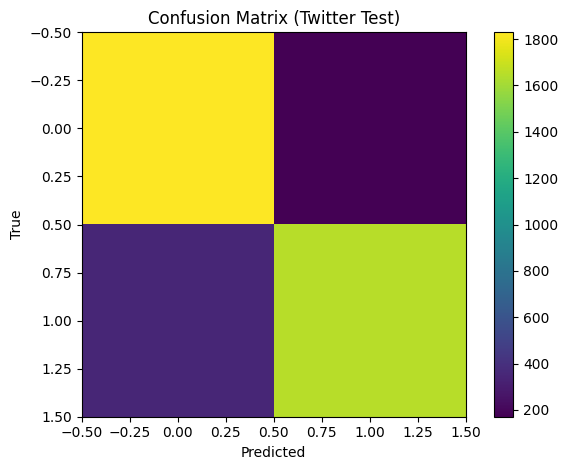

In [16]:
# =============================
# EVALUATE ON TWITTER TEST ONLY
# (tokenized["test"] is twitter_test_only.csv)
# =============================
import os, json, numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Predict
pred = trainer.predict(tokenized["test"])
y_true = pred.label_ids
y_pred = pred.predictions.argmax(axis=-1)

# Metrics dict (accuracy, f1, precision, recall) using the same function as training
test_metrics = compute_metrics((pred.predictions, y_true))
print("=== Twitter Test Metrics ===")
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}")

# Save metrics
with open(f"{OUTPUT_DIR}/metrics_test_twitter.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

# Classification report (per-class precision/recall/f1)
report_txt = classification_report(y_true, y_pred, digits=4)
print("\n=== Classification Report (Twitter Test) ===")
print(report_txt)
with open(f"{OUTPUT_DIR}/classification_report_twitter.txt", "w") as f:
    f.write(report_txt)

# Confusion matrix (CSV + plot)
cm = confusion_matrix(y_true, y_pred)
np.savetxt(f"{OUTPUT_DIR}/confusion_matrix_twitter.csv", cm, fmt="%d", delimiter=",")

plt.figure()
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix (Twitter Test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix_twitter.png", dpi=150)
plt.show()

# Load raw test CSV to attach texts next to predictions
tw_test_df = pd.read_csv("/content/twitter_test_only.csv")
probs = (pred.predictions - pred.predictions.max(axis=1, keepdims=True))
probs = np.exp(probs) / np.exp(probs).sum(axis=1, keepdims=True)

out_df = tw_test_df.copy()
out_df["y_true"] = y_true
out_df["y_pred"] = y_pred
out_df["pred_confidence"] = probs.max(axis=1)

out_df["is_correct"] = (out_df["y_true"] == out_df["y_pred"]).astype(int)

out_path = f"{OUTPUT_DIR}/twitter_test_predictions.csv"
out_df.to_csv(out_path, index=False)